# Práctica 1 — Síntesis de voz

**Equipo:** _(poned aquí vuestro número y los nombres)_

Este cuaderno es el punto de partida. Ejecutad las celdas en orden.
Donde pone `# TAREA` tenéis que escribir o decidir algo vosotros;
el resto es andamiaje y funciona tal cual.

Las funciones de apoyo están en `scripts/`. Podéis abrirlas y leerlas:
están comentadas y explican por qué cada medida se toma como se toma.

## 0. Puesta en marcha

Esta celda crea las carpetas, fija `HF_HOME` (la caché por defecto del
workspace es de solo lectura) y deja `scripts/` accesible.
Ejecutadla **siempre la primera**, también al reabrir el cuaderno.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd() / 'scripts'))

from tts_util import preparar_entorno, sin_ruido, cargar_frases, resumen_corpus
from tts_util import BASE, AUDIO, RES, MOS, EQUIPO

preparar_entorno()

Entorno : local
Trabajo : C:\Users\alvar\Desktop\ZCODE\Ing. Informática\4 CURSO\PROCESAMIENTO\PRÁCTICAS\P1\repo-p1
Computo : cpu  (sin GPU: todo ira mas lento)


WindowsPath('C:/Users/alvar/Desktop/ZCODE/Ing. Informática/4 CURSO/PROCESAMIENTO/PRÁCTICAS/P1/repo-p1')

In [2]:
import pandas as pd
import numpy as np
from IPython.display import Audio, display

import adaptadores, analisis, evaluacion

---
# Sesión 1 — Corpus y candidatos

## Tarea 1.1 — Corpus de frases

Todas las medidas de la práctica se hacen sobre las mismas 20 frases.
Partid de `frases_ejemplo.tsv`, copiadlo como `frases.tsv` y completadlo
con frases de **vuestro dominio**.

Composición obligatoria: 6 `decl`, 4 `int_abs`, 4 `int_parc`,
3 `cifras`, 3 `siglas`.

La columna `leida` es cómo **debería** pronunciarse la frase, en letras y
sin puntuación. Es la referencia para medir la inteligibilidad en la S3.

In [3]:
# TAREA 1.1 — ejecutad esto una vez para crear vuestro frases.tsv,
# después editadlo desde el panel de ficheros de JupyterLab.
import shutil
destino = BASE / 'frases.tsv'
if not destino.exists():
    shutil.copy('frases_ejemplo.tsv', destino)
    print(f'Creado {destino}. Editadlo y volved aquí.')
else:
    print(f'{destino} ya existe.')

C:\Users\alvar\Desktop\ZCODE\Ing. Informática\4 CURSO\PROCESAMIENTO\PRÁCTICAS\P1\repo-p1\frases.tsv ya existe.


In [4]:
frases = cargar_frases()
resumen_corpus(frases)

20 frases en total

categoria   hay  pide
decl          6     6
int_abs       4     4
int_parc      4     4
cifras        3     3
siglas        3     3


## Tarea 1.2 — Candidatos

Al menos **tres sistemas** que funcionen, de **al menos dos familias**
distintas. Piper viene preparado; el segundo es un ejemplo que puede o no
funcionar; el tercero lo buscáis vosotros.

Si un candidato no arranca: anotad el error exacto, dedicadle como mucho
30 minutos y descartadlo. Un sistema descartado con su diagnóstico cuenta
como candidato explorado en el informe.

In [5]:
CANDIDATOS = {}

# Candidato A — Piper (CPU). Descarga la voz la primera vez (~74 MB).
adaptadores.registrar(CANDIDATOS, 'piper_sharvard',
                      adaptadores.crear_piper, 'es_ES-sharvard-medium')

# Candidato B — MMS-TTS (GPU). Si falla, anotad el error y seguid.
adaptadores.registrar(CANDIDATOS, 'mms_spa',
                      adaptadores.crear_mms)

# TAREA 1.2 — Candidato C: Kokoro-82M (StyleTTS 2, otra familia distinta
# de Piper y MMS, que son VITS). Descarga el modelo la primera vez (~330 MB).
# Voces en español: ef_dora (mujer), em_alex y em_santa (hombres).
# Elegida em_santa tras escuchar las tres (ver ficha de la 1.3).
adaptadores.registrar(CANDIDATOS, 'kokoro_santa',
                      adaptadores.crear_kokoro, 'em_santa')

print()
print('Candidatos activos:', list(CANDIDATOS))

es_ES-sharvard-medium ya descargada (77 MB)
[ OK ] piper_sharvard


c:\Users\alvar\Desktop\ZCODE\Ing. Informática\4 CURSO\PROCESAMIENTO\PRÁCTICAS\P1\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

[ OK ] mms_spa


c:\Users\alvar\Desktop\ZCODE\Ing. Informática\4 CURSO\PROCESAMIENTO\PRÁCTICAS\P1\.venv\Lib\site-packages\torch\nn\modules\rnn.py:1011: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)
c:\Users\alvar\Desktop\ZCODE\Ing. Informática\4 CURSO\PROCESAMIENTO\PRÁCTICAS\P1\.venv\Lib\site-packages\torch\nn\utils\weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


[ OK ] kokoro_santa

Candidatos activos: ['piper_sharvard', 'mms_spa', 'kokoro_santa']


In [5]:
# Prueba rápida: una frase con cada candidato
for nombre, tts in CANDIDATOS.items():
    ruta = AUDIO / 'prueba' / f'{nombre}.wav'
    tts(frases[0]['texto'], ruta)
    print(nombre)
    display(Audio(str(ruta)))

## Tarea 1.3 — Ficha de cada candidato

Rellenad esta tabla en el informe (aquí podéis ir tomando notas).
Las tres primeras columnas se completan hoy; la calidad, en la S3.

| Criterio | Dónde se mira |
|---|---|
| Licencia y uso comercial | *model card*, fichero LICENSE del repositorio |
| Español: variedad, nº de voces | *model card* y vuestra escucha |
| Memoria ocupada | `torch.cuda.memory_allocated()` o `nvidia-smi` |
| Velocidad (RTF y carga) | tarea 1.4 |
| Mantenimiento | última versión, actividad, dependencias |
| Calidad | sesión 3 |

### Notas 1.3

| | Piper (es_ES-sharvard-medium) | MMS-TTS (facebook/mms-tts-spa) | Kokoro-82M (em_santa) |
|---|---|---|---|
| Arquitectura | VITS, exportado a ONNX | VITS (transformers) | StyleTTS 2 + iSTFTNet |
| Licencia código | GPL-3.0 (piper-tts 1.8.0) | Apache-2.0 (transformers) | Apache-2.0 (kokoro 0.9.4), pero para español usa phonemizer y espeak-ng, que son GPL-3.0 |
| Licencia voz/pesos | CC BY 3.0 | CC BY-NC 4.0 | Apache-2.0 |
| Uso comercial | Sí, citando la voz (y la GPL si se distribuye) | No | Sí (misma pega de la GPL que Piper) |
| Variedad | es_ES | spa, no dice cuál. Datos de MMS: lecturas del Nuevo Testamento | No documentada. Los fonemas de espeak son de es_ES (con θ) |
| Voces | 2 (M y F), usamos la M | 1 | 3 (ef_dora, em_alex, em_santa) |
| Disco | 77 MB | 145 MB, 36,3 M parámetros | 327 MB, 81,8 M parámetros |
| RAM al cargar | +99 MB | +341 MB | +1140 MB |
| RAM pico sintetizando | +189 MB | +458 MB | +1165 MB |
| Última versión | 1.8.0, sep 2026 (varias versiones este verano) | pesos de 2023, repo fairseq archivado en mar 2026 | 0.9.4, abr 2025 |
| Parámetros prosódicos | length_scale, noise_scale, noise_w_scale | ninguno | speed |
| Velocidad (1.4) | RTF 0,040, carga 4,1 s | RTF 0,172, carga 1,2 s | RTF 0,260, carga 1,5 s |
| Calidad | S3 | S3 | S3 |

Kokoro como candidato C: es de otra arquitectura (Piper y MMS son VITS los dos), deja uso comercial y va bien en CPU. De sus tres voces en español nos quedamos con em_santa después de escucharlas con las mismas frases: es la que mejor se oye, más grave y con más volumen.

Memoria: en local no tenemos CUDA, así que medimos RAM del proceso con psutil en vez de `torch.cuda.memory_allocated()`. Cada modelo en un proceso aparte, con las librerías ya importadas antes de cargar, y el pico durante 3 síntesis de la frase más larga. Hay que repetirlo en GPU en NIMROD.

Problemas en Windows: piper y kokoro fallaban con rutas con tildes (espeak-ng no encuentra sus datos y cierra el kernel) y la DLL de spacy la bloquea Windows. Está resuelto en `adaptadores.py`.

In [ ]:
# Memoria en GPU de los modelos de PyTorch (MMS y Kokoro).
# Solo mide si hay CUDA (en NIMROD); en un portátil sin GPU se salta.
import gc
import torch

if torch.cuda.is_available():
    larga = max(frases, key=lambda f: len(f['texto']))['texto']
    for nombre, constructor, *args in [('mms_spa', adaptadores.crear_mms),
                                       ('kokoro_santa', adaptadores.crear_kokoro, 'em_santa')]:
        gc.collect(); torch.cuda.empty_cache()
        antes = torch.cuda.memory_allocated()
        tts = constructor(*args)
        modelo = torch.cuda.memory_allocated() - antes
        torch.cuda.reset_peak_memory_stats()
        tts(larga, AUDIO / 'prueba' / '_mem_gpu.wav')
        pico = torch.cuda.max_memory_allocated() - antes
        print(f'{nombre:13s} GPU: modelo {modelo / 2**20:6.0f} MB, '
              f'pico sintetizando {pico / 2**20:6.0f} MB')
        del tts
    gc.collect(); torch.cuda.empty_cache()
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('Sin CUDA: la memoria en GPU se mide en NIMROD.')

## Tarea 1.4 — Velocidad

`medir_rtf` separa la carga del modelo del tiempo de síntesis, descarta
una primera llamada de calentamiento y toma la mediana de varias
repeticiones. Las tres cosas hay que saber justificarlas en la defensa.

In [ ]:
filas = []
for nombre, tts in CANDIDATOS.items():
    print(f'Midiendo {nombre} ...')
    for f in analisis.medir_rtf(tts, frases, AUDIO / nombre):
        filas.append(dict(sistema=nombre, **f))

rtf = pd.DataFrame(filas)
rtf.to_csv(RES / 'rtf.csv', index=False)
rtf.groupby('sistema')[['rtf', 'dur']].describe().round(3)

In [12]:
# Tiempo de CARGA de cada modelo, que se reporta aparte del RTF.
# Los modelos ya se cargaron una vez en la tarea 1.2, así que esto mide una
# carga «en caliente»: librerías ya importadas y ficheros en la caché del disco.
CONSTRUCTORES = {
    'piper_sharvard': (adaptadores.crear_piper, 'es_ES-sharvard-medium'),
    'mms_spa':        (adaptadores.crear_mms,),
    'kokoro_santa':   (adaptadores.crear_kokoro, 'em_santa'),
}
carga = {}
for nombre, (constructor, *args) in CONSTRUCTORES.items():
    _, carga[nombre] = analisis.medir_carga(constructor, *args)
    print(f'Carga de {nombre:15s}: {carga[nombre]:6.2f} s')

es_ES-sharvard-medium ya descargada (77 MB)
Carga de piper_sharvard :   3.92 s


Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

Carga de mms_spa        :   1.57 s


c:\Users\alvar\Desktop\ZCODE\Ing. Informática\4 CURSO\PROCESAMIENTO\PRÁCTICAS\P1\.venv\Lib\site-packages\torch\nn\modules\rnn.py:1011: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)
c:\Users\alvar\Desktop\ZCODE\Ing. Informática\4 CURSO\PROCESAMIENTO\PRÁCTICAS\P1\.venv\Lib\site-packages\torch\nn\utils\weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Carga de kokoro_santa   :   1.47 s


In [13]:
# TAREA 1.4 — Repetid la medida de Piper con usar_gpu=True y comparad.
# ¿Gana siempre la GPU con un modelo pequeño? Justificadlo.
#
# Solo se mide si onnxruntime tiene CUDA: si no, usar_gpu=True se ejecuta en
# CPU sin avisar y la «comparación» sería CPU contra CPU.
import onnxruntime as ort

if 'CUDAExecutionProvider' in ort.get_available_providers():
    piper_gpu, carga['piper_gpu'] = analisis.medir_carga(
        adaptadores.crear_piper, 'es_ES-sharvard-medium', usar_gpu=True)
    filas = [dict(sistema='piper_gpu', **f)
             for f in analisis.medir_rtf(piper_gpu, frases, AUDIO / 'piper_gpu')]
    rtf = pd.concat([rtf[rtf.sistema != 'piper_gpu'], pd.DataFrame(filas)],
                    ignore_index=True)
    rtf.to_csv(RES / 'rtf.csv', index=False)
    print(f"Carga de piper_gpu: {carga['piper_gpu']} s")
    print(rtf[rtf.sistema.str.startswith('piper')].groupby('sistema').rtf.median())
else:
    print('onnxruntime no tiene CUDA en este equipo '
          f'(proveedores: {ort.get_available_providers()}).')
    print('La comparación CPU/GPU de Piper hay que hacerla en NIMROD.')

onnxruntime no tiene CUDA en este equipo (proveedores: ['AzureExecutionProvider', 'CPUExecutionProvider']).
La comparación CPU/GPU de Piper hay que hacerla en NIMROD.


In [ ]:
# Resumen de velocidad para el informe (S3): RTF mediano con su rango
# intercuartílico (p25-p75) entre las 20 frases, y tiempo de carga.
resumen_vel = rtf.groupby('sistema').agg(
    rtf_mediano=('rtf', 'median'),
    rtf_p25=('rtf', lambda x: x.quantile(0.25)),
    rtf_p75=('rtf', lambda x: x.quantile(0.75)),
    t_sintesis_mediano=('t_sintesis', 'median'),
)
resumen_vel['carga_s'] = pd.Series(carga)
resumen_vel = resumen_vel.round(3).sort_values('rtf_mediano')
resumen_vel.to_csv(RES / 'velocidad.csv')
resumen_vel

,rtf_mediano,rtf_p25,rtf_p75,t_sintesis_mediano,carga_s
sistema,,,,,
piper_sharvard,0.040,0.039,0.041,0.108,3.923
mms_spa,0.172,0.168,0.185,0.695,1.575
kokoro_santa,0.260,0.256,0.267,0.852,1.466


### Notas 1.4

Medido en el portátil, en CPU (16 núcleos).

| | RTF mediano (p25-p75) | síntesis por frase | carga |
|---|---|---|---|
| Piper | 0,040 (0,039-0,041) | 0,11 s | 4,07 s |
| MMS | 0,172 (0,168-0,185) | 0,70 s | 1,25 s |
| Kokoro | 0,260 (0,256-0,267) | 0,85 s | 1,54 s |

Los tres tienen RTF < 1, así que valen para tiempo real. Piper es unas 25 veces más rápido que el tiempo real, 4 veces más que MMS y 6,5 más que Kokoro. En cambio es el que más tarda en cargar; probamos a cambiar el número de hilos y no cambia nada, el tiempo se va en crear la sesión de onnxruntime. La carga está medida con los modelos ya cargados antes una vez (la primera vez tarda más porque importa librerías y descarga el modelo).

Por qué se mide así:
- Carga aparte: se hace una vez y luego se sintetizan muchas frases. Con nuestros datos, para una sola frase Piper tardaría más en total que MMS (4,2 s contra 1,9 s), pero a partir de unas 5 frases ya es más rápido que MMS y a partir de 4 que Kokoro. Si se mezclara la carga con el RTF, el resultado dependería de cuántas frases se midan.
- Calentamiento: la primera síntesis es más lenta porque reserva memoria e inicializa cosas. Lo comprobamos con la misma frase 8 veces: en Piper la primera tardó unas 3 veces más que el resto, en MMS 1,5 y en Kokoro 1,2.
- Mediana: los retrasos (otro proceso, el antivirus...) solo pueden hacer que una medida salga más lenta, y con la media un solo caso así sube el resultado. La mediana no se ve afectada.

GPU: en el portátil onnxruntime no tiene CUDA y con `usar_gpu=True` Piper sigue en CPU sin dar error, por eso la celda de arriba no mide nada aquí. Hay que hacerlo en NIMROD. Lo que esperamos: con un modelo pequeño y frases cortas la GPU no tiene por qué ganar, porque hay que pasar los datos a la GPU y volver, y la parte de espeak sigue en CPU.

---
# Sesión 2 — Control prosódico

La pregunta de esta sesión no es si suena distinto, sino **qué cambia y
qué no** al tocar los parámetros o el texto.

`analisis.analiza(ruta)` devuelve la duración, la F0 mediana, el recorrido
de F0 en semitonos y `final_st`: el movimiento de los últimos 300 ms.
Positivo = termina subiendo; negativo = termina bajando.

## Tarea 2.1 — ¿Es lineal el control de velocidad?

In [14]:
escalas = [0.6, 0.8, 1.0, 1.2, 1.4, 1.6]
decl = [f for f in frases if f['categoria'] == 'decl']

tts = CANDIDATOS['piper_sharvard']   # solo sistemas con admite_parametros
filas = []
for fr in decl:
    for e in escalas:
        ruta = AUDIO / 'velocidad' / f"{fr['id']}_{e}.wav"
        tts(fr['texto'], ruta, length_scale=e)
        filas.append(dict(id=fr['id'], escala=e, dur=analisis.analiza(ruta)['dur']))

vel = pd.DataFrame(filas)
base = vel[vel.escala == 1.0].set_index('id').dur
vel['dur_rel'] = vel.dur / vel.id.map(base)
vel.groupby('escala').dur_rel.mean().round(3)

escala
0.6    0.692
0.8    0.879
1.0    1.000
1.2    1.118
1.4    1.281
1.6    1.469
Name: dur_rel, dtype: float64

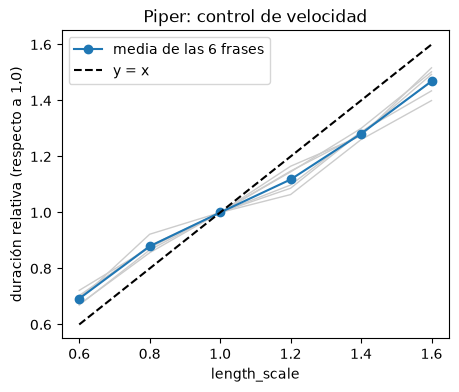

In [15]:
# TAREA 2.1 — Dibujad dur_rel frente a escala junto con la diagonal y = x.
# ¿Se ajusta? ¿Se alargan igual los silencios que los sonidos?
# ¿A partir de qué valor la voz deja de ser aceptable? (escuchadlo)
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))
for _, g in vel.groupby('id'):
    ax.plot(g.escala, g.dur_rel, color='0.8', lw=1)
media = vel.groupby('escala').dur_rel.mean()
ax.plot(media.index, media.values, 'o-', label='media de las 6 frases')
ax.plot(escalas, escalas, 'k--', label='y = x')
ax.set_xlabel('length_scale')
ax.set_ylabel('duración relativa (respecto a 1,0)')
ax.set_title('Piper: control de velocidad')
ax.legend()
fig.savefig(RES / 'velocidad_piper.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
# Sonidos frente a silencios. Se separan los tramos con voz de las pausas
# por energía (librosa): cuenta como pausa un hueco interno de 50 ms o más,
# 35 dB por debajo del máximo. El silencio de los bordes no cuenta.
import librosa

def pausas(ruta, top_db=35, minima=0.05):
    y, sr = librosa.load(str(ruta), sr=None)
    tramos = librosa.effects.split(y, top_db=top_db,
                                   frame_length=1024, hop_length=256) / sr
    huecos = tramos[1:, 0] - tramos[:-1, 1]
    huecos = huecos[huecos >= minima]
    voz = tramos[-1, 1] - tramos[0, 0] - huecos.sum()
    return dict(voz=voz, pausas=huecos.sum(), n_pausas=len(huecos))

sil = pd.DataFrame([dict(id=fr['id'], escala=e,
                         **pausas(AUDIO / 'velocidad' / f"{fr['id']}_{e}.wav"))
                    for fr in decl for e in escalas])
sil['voz_rel'] = sil.voz / sil.id.map(sil[sil.escala == 1.0].set_index('id').voz)
sil.to_csv(RES / 'velocidad_pausas.csv', index=False)
sil.groupby('escala')[['voz_rel', 'pausas', 'n_pausas']].mean().round(3)

,voz_rel,pausas,n_pausas
escala,,,
0.6,0.701,0.012,0.167
0.8,0.888,0.023,0.333
1.0,1.000,0.037,0.333
1.2,1.111,0.056,0.500
1.4,1.270,0.070,0.833
1.6,1.442,0.099,0.667


In [17]:
# Para escuchar: la misma frase a todas las velocidades.
# Cambiad el índice de decl[...] para oír otra frase.
fr = decl[0]
print(fr['texto'])
for e in escalas:
    print('length_scale =', e)
    display(Audio(str(AUDIO / 'velocidad' / f"{fr['id']}_{e}.wav")))

La secretaría abre de nueve a dos.
length_scale = 0.6


length_scale = 0.8


length_scale = 1.0


length_scale = 1.2


length_scale = 1.4


length_scale = 1.6


In [19]:
# TAREA 2.1 — Lo mismo con Kokoro, el otro candidato con admite_parametros
# (MMS no admite parámetros). El adaptador convierte length_scale en
# speed = 1/length_scale, así que las escalas se comparan con las de Piper.
tts_k = CANDIDATOS['kokoro_santa']
filas = []
for fr in decl:
    for e in escalas:
        ruta = AUDIO / 'velocidad_kokoro' / f"{fr['id']}_{e}.wav"
        tts_k(fr['texto'], ruta, length_scale=e)
        filas.append(dict(id=fr['id'], escala=e, dur=analisis.analiza(ruta)['dur']))

vel_k = pd.DataFrame(filas)
base_k = vel_k[vel_k.escala == 1.0].set_index('id').dur
vel_k['dur_rel'] = vel_k.dur / vel_k.id.map(base_k)

# Voz y pausas con la misma función pausas() que para Piper
sil_k = pd.DataFrame([dict(id=fr['id'], escala=e,
                           **pausas(AUDIO / 'velocidad_kokoro' / f"{fr['id']}_{e}.wav"))
                      for fr in decl for e in escalas])
sil_k['voz_rel'] = sil_k.voz / sil_k.id.map(sil_k[sil_k.escala == 1.0].set_index('id').voz)
sil_k.to_csv(RES / 'velocidad_pausas_kokoro.csv', index=False)

# Duraciones de los dos sistemas en una sola tabla, para el informe
pd.concat([vel.assign(sistema='piper_sharvard'),
           vel_k.assign(sistema='kokoro_santa')]).to_csv(RES / 'velocidad_dur.csv', index=False)

pd.DataFrame({
    'piper_dur_rel':  vel.groupby('escala').dur_rel.mean(),
    'kokoro_dur_rel': vel_k.groupby('escala').dur_rel.mean(),
    'kokoro_voz_rel': sil_k.groupby('escala').voz_rel.mean(),
    'kokoro_pausas':  sil_k.groupby('escala').pausas.mean(),
    'kokoro_n_pausas': sil_k.groupby('escala').n_pausas.mean(),
}).round(3)

,piper_dur_rel,kokoro_dur_rel,kokoro_voz_rel,kokoro_pausas,kokoro_n_pausas
escala,,,,,
0.6,0.692,0.597,0.583,0.000,0.000
0.8,0.879,0.849,0.848,0.023,0.333
1.0,1.000,1.000,1.000,0.041,0.500
1.2,1.118,1.144,1.139,0.096,1.333
1.4,1.281,1.411,1.407,0.171,2.333
1.6,1.469,1.599,1.570,0.299,3.833


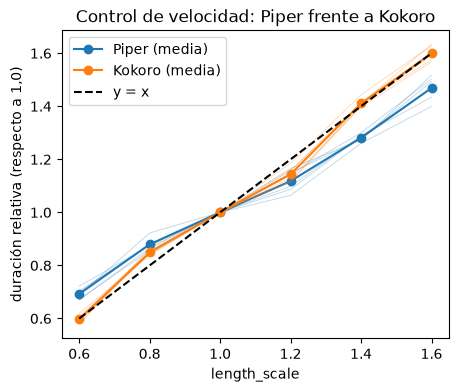

In [20]:
# Piper y Kokoro en la misma figura, con la diagonal y = x
fig, ax = plt.subplots(figsize=(5, 4))
for datos, color, nombre in [(vel, 'C0', 'Piper'), (vel_k, 'C1', 'Kokoro')]:
    for _, g in datos.groupby('id'):
        ax.plot(g.escala, g.dur_rel, color=color, lw=0.6, alpha=0.3)
    media = datos.groupby('escala').dur_rel.mean()
    ax.plot(media.index, media.values, 'o-', color=color, label=f'{nombre} (media)')
ax.plot(escalas, escalas, 'k--', label='y = x')
ax.set_xlabel('length_scale')
ax.set_ylabel('duración relativa (respecto a 1,0)')
ax.set_title('Control de velocidad: Piper frente a Kokoro')
ax.legend()
fig.savefig(RES / 'velocidad_comparada.png', dpi=150, bbox_inches='tight')
plt.show()

In [21]:
# Para escuchar Kokoro: la misma frase a todas las velocidades.
fr = decl[0]
print(fr['texto'])
for e in escalas:
    print('length_scale =', e)
    display(Audio(str(AUDIO / 'velocidad_kokoro' / f"{fr['id']}_{e}.wav")))

La secretaría abre de nueve a dos.
length_scale = 0.6


length_scale = 0.8


length_scale = 1.0


length_scale = 1.2


length_scale = 1.4


length_scale = 1.6


### Notas 2.1

**Piper**

Piper con las 6 frases declarativas y length_scale de 0,6 a 1,6. Medias de las 6 frases.

| length_scale | 0,6 | 0,8 | 1,0 | 1,2 | 1,4 | 1,6 |
|---|---|---|---|---|---|---|
| duración total relativa | 0,68 | 0,87 | 1,00 | 1,10 | 1,29 | 1,43 |
| duración de la voz relativa (sin pausas) | 0,69 | 0,88 | 1,00 | 1,11 | 1,27 | 1,42 |
| pausas (s) | 0,00 | 0,03 | 0,04 | 0,04 | 0,09 | 0,10 |
| nº de pausas | 0,00 | 0,33 | 0,33 | 0,33 | 0,67 | 0,83 |

No sigue la diagonal. Se queda corto por los dos lados: con 0,6 la frase solo se acorta un 32 % y con 1,6 solo se alarga un 43 %. Las 6 frases dan casi lo mismo, así que es cosa del modelo y no de la frase. En la nota de `analisis.py` (medido en NIMROD) salía parecido, 0,69 y 1,51. Si se quiere una velocidad concreta hay que probar valores, no vale con poner el número.

Silencios: separamos voz y pausas por energía (huecos de 50 ms o más, a 35 dB del máximo, sin contar los bordes). La voz crece casi igual que la frase entera (1,42 frente a 1,43 con 1,6), así que el alargamiento está casi todo en los sonidos. Nuestras declarativas no tienen comas y las pausas son muy cortas, como mucho 0,1 s. Aun así no crecen en proporción: con 0,6 desaparecen y con 1,6 pasan de 0,04 s a 0,10 s. Con tan poco silencio este dato cambia un poco según el umbral, así que no lo damos por seguro.

Al escucharlo: se entiende bien en todas las velocidades, también cambiando de frase. Con 1,4 y sobre todo con 1,6 ya empieza a sonar arrastrada y algo robótica. Por la parte rápida, hasta 0,6, sigue siendo aceptable.

**Kokoro**

Las mismas 6 frases con Kokoro (`em_santa`). El adaptador convierte `length_scale` en `speed = 1/length_scale`, así que las escalas son las mismas. Medias de las 6 frases:

| length_scale | 0,6 | 0,8 | 1,0 | 1,2 | 1,4 | 1,6 |
|---|---|---|---|---|---|---|
| duración total relativa — Piper | 0,68 | 0,87 | 1,00 | 1,10 | 1,29 | 1,43 |
| duración total relativa — Kokoro | 0,60 | 0,85 | 1,00 | 1,14 | 1,41 | 1,60 |
| duración de la voz relativa — Kokoro | 0,58 | 0,85 | 1,00 | 1,14 | 1,41 | 1,57 |
| pausas — Kokoro (s) | 0,00 | 0,02 | 0,04 | 0,10 | 0,17 | 0,30 |
| nº de pausas — Kokoro | 0,00 | 0,33 | 0,50 | 1,33 | 2,33 | 3,83 |

Kokoro sí sigue la diagonal: con 0,6 da 0,60 y con 1,6 da 1,60. En los valores intermedios se separa un poco (0,85 con 0,8 y 1,14 con 1,2), pero mucho menos que Piper. Las 6 frases vuelven a dar casi lo mismo: entre 0,58 y 0,62 con 0,6 y entre 1,57 y 1,63 con 1,6. Tiene sentido, porque Kokoro divide directamente entre `speed` la duración que predice para cada fonema. Con Kokoro se puede pedir una velocidad y obtenerla; con Piper hay que calibrarla.

Silencios: aquí es distinto que en Piper. Las pausas crecen mucho más que la voz: con 1,6 pasan de 0,04 s a 0,30 s (unas 7 veces) y de 0,5 a casi 4 huecos por frase. Como las frases no tienen comas, sospechamos que muchos de esos huecos no son pausas entre palabras sino cierres de oclusivas (p, t, k) que al alargarse superan los 50 ms; habría que comprobarlo en el espectrograma. Aun así son poco tiempo: la voz sola crece 1,57, casi lo mismo que la frase entera.

La referencia de 1,0 es fiable: repetimos f01 tres veces y las tres duran exactamente lo mismo (58 200 muestras), aunque la onda no es idéntica (lo vemos en la 2.2). En Piper, en cambio, la duración sí varía con el ruido por defecto.

Al escucharlo (f01, «La secretaría abre de nueve a dos.»): Kokoro se comporta al revés que Piper. Por la parte rápida es donde peor suena: con 0,6 se come el artículo «La» del principio y cuesta entenderla, así que el límite aceptable por ese lado está en torno a 0,8. Por la parte lenta suena incluso mejor que a velocidad normal: con 1,4 y 1,6 no se nota arrastrada ni robótica como Piper. Encaja con las medidas: con 0,6 Kokoro acorta de verdad la frase al 60 % (Piper solo al 68 %), así que va bastante más rápido, y al ralentizar alarga los fonemas de forma más natural.

MMS no admite parámetros de velocidad, así que no entra en esta tarea.

## Tarea 2.2 — ¿Es determinista el sistema?

In [ ]:
# TAREA 2.2 — Sintetizad la MISMA frase 5 veces en tres condiciones:
#   a) parámetros por defecto
#   b) noise_scale=0.0, noise_w_scale=0.0
#   c) noise_scale=1.0, noise_w_scale=1.0
# Para cada grupo, desviación típica de la duración y del rango_st.
# ¿Con variabilidad cero salen audios idénticos? ¿Suena más monótona?

## Tarea 2.3 — Modalidad: ¿pregunta cuando debe?

Ningún sistema tiene un parámetro «pregunta»: la entonación se infiere de
la puntuación. Comprobad si lo hace bien.

In [ ]:
fr = decl[0]['texto'].rstrip('.')
versiones = {'.': fr + '.', '?': '¿' + fr + '?', '!': '¡' + fr + '!'}

etiquetadas = []
for nombre, tts in CANDIDATOS.items():
    for marca, texto in versiones.items():
        ruta = AUDIO / 'modalidad' / f'{nombre}_{marca.strip(chr(46))or "pt"}.wav'
        tts(texto, ruta)
        a = analisis.analiza(ruta)
        print(f'{nombre:20s} {marca}  final_st = {a["final_st"]:+.2f}')
        if nombre == 'piper_sharvard':
            etiquetadas.append((marca, ruta))

analisis.dibuja_contornos(etiquetadas, 'Modalidad — Piper',
                          RES / 'modalidad_piper.png');

In [ ]:
# TAREA 2.3 — Aplicad lo mismo a vuestras 4 int_abs y 4 int_parc.
# En español la interrogativa absoluta suele terminar en ascenso y la
# parcial no necesariamente: ¿lo reproduce cada sistema?

## Tarea 2.4 — Foco: ¿se puede enfatizar una palabra?

Los sistemas no tienen control de foco. Solo podéis intentarlo desde el
texto: mayúsculas, comas, reordenar, repetir, partir en dos oraciones.
Que no funcione nada es un resultado válido y hay que documentarlo.

In [ ]:
# TAREA 2.4 — Probad al menos tres trucos sobre una frase, poniendo el
# énfasis en tres palabras distintas. Medid F0 máxima y duración de la
# palabra objetivo en cada versión.

## Tarea 2.5 — Normalización de texto

In [ ]:
# Escuchad las frases de las categorías cifras y siglas en los 3 sistemas
for fr in [f for f in frases if f['categoria'] in ('cifras', 'siglas')]:
    print(fr['texto'])
    for nombre in CANDIDATOS:
        display(Audio(str(AUDIO / nombre / f"{fr['id']}.wav")))

In [ ]:
# TAREA 2.5 — Escribid normaliza(texto) para convertir fechas, horas,
# importes y siglas a letras ANTES de sintetizar, y comparad el resultado.

def normaliza(texto):
    # ... vuestro código
    return texto

---
# Sesión 3 — Evaluación de calidad

Tres vías que responden a preguntas distintas. Lo interesante aparece
cuando no coinciden.

## Tarea 3.1 — Inteligibilidad

Se transcribe la voz sintética con el reconocedor de referencia de la
asignatura (el mismo para todos los equipos) y se compara con la columna
`leida`. Ocupa VRAM: cargadlo cuando vayáis a usarlo.

In [ ]:
intel = evaluacion.mide_inteligibilidad(CANDIDATOS, frases)
intel.to_csv(RES / 'inteligibilidad.csv', index=False)
intel.pivot_table(index='categoria', columns='sistema', values='wer').round(3)

**Separad el habla normal de las cifras y siglas.** En esas dos categorías
buena parte del WER no es falta de inteligibilidad, sino desacuerdo entre
vuestra columna `leida` y cómo escribe el reconocedor.

In [ ]:
evaluacion.resumen_wer(intel)

Ahora revisad **a mano** las frases difíciles. Para cada una, decidid si el
error es artefacto de convención (la voz se entendió, se escribió distinto)
o fallo real de síntesis (la voz dijo algo que no era). Esa clasificación
va al informe.

In [ ]:
evaluacion.revisar(intel)

In [ ]:
# TAREA 3.1 — Revisad A MANO las transcripciones de la categoría cifras.
# ¿Cuántos "errores" son en realidad '30' frente a 'treinta'?
intel[intel.categoria == 'cifras'][['sistema', 'referencia', 'hipotesis', 'wer']]

## Tarea 3.2 — MOS

Panel cruzado y ciego: vuestras muestras las puntúan otros equipos.
Elegid 5 frases (al menos una de cada categoría).

In [ ]:
# TAREA 3.2 — poned aquí vuestros 5 ids
elegidas = ['f01', 'f03', 'f04', 'f05', 'f06']

clave = evaluacion.preparar_mos(CANDIDATOS, frases, elegidas)

In [ ]:
# Cuando recibáis las notas (CSV con columnas evaluador, muestra, nota):
# evaluacion.analiza_mos(RES / 'mos_recibidas.csv')

## Tarea 3.3 — Consistencia de la voz

In [ ]:
emb, intra, entre = evaluacion.consistencia(CANDIDATOS, frases)

In [ ]:
# TAREA 3.3 — Comparad la consistencia de las frases interrogativas frente
# a las declarativas. ¿Cambia la "identidad" de la voz cuando pregunta?

## Tarea 3.4 — Reflexión ética

500-800 palabras en el informe, con al menos dos fuentes citadas.
Apoyaos en lo que habéis oído esta semana: ¿podrían estas voces engañar a
alguien? ¿En qué se nota que son sintéticas?

---
## Decisión final

¿Qué sistema usaríais en el asistente de vuestro dominio y por qué?
Ponderad calidad, velocidad, recursos y licencia. «El de mayor MOS» no
basta si es diez veces más lento o su licencia no lo permite.

In [ ]:
# Resumen de todas las medidas, para la discusión del informe
resumen = rtf.groupby('sistema').rtf.median().rename('rtf_mediano').to_frame()
resumen['wer_intel'] = intel.groupby('sistema').wer.mean()
resumen['consistencia'] = pd.Series(intra)
resumen.round(3)